# Notebook 1 — EDA y preprocesado

Este notebook contiene la exploración descriptiva (EDA) del dataset y aplica el
pipeline de limpieza antes de generar los ficheros de entrenamiento y test
para las tareas de clasificación y regresión.

Toda la lógica de limpieza se encuentra en `src/clean_data.py`; que servirá 
de librería para realizar la limpieza y creación de los datasets procesados
para cada una de las tareas.

## Índice

0. Configuración
1. Carga y primera inspección del dataset.
2. EDA: estructura, variable objetivo, valores nulos, variables académicas,
   demográficas, socioeconómicas, categóricas de alta cardinalidad,
   multicolinealidad y variables macro.
3. Aplicación del pipeline de limpieza paso a paso.
4. Generación de los datasets de clasificación y regresión.
5. Verificación final.

## 0. Configuración

Añadimos `src/` al `sys.path` para importar los módulos del proyecto y
fijamos un estilo uniforme para los gráficos.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import clean_data
from configuracion import RAW_DATA_PATH, PROCESSED_DIR

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100

print(f'Raíz del proyecto: {ROOT}')
print(f'Dataset: {RAW_DATA_PATH}')
print(f'Directorio salida: {PROCESSED_DIR}')

Raíz del proyecto: c:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning
Dataset: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\data\rendimiento_estudiantes.csv
Directorio salida: C:\Users\mb6ja\OneDrive\Documentos\ICAI\2\Machine_Learning\Proyecto_final_Machine_Learning\data\processed


## 1. Carga y primera inspección

In [2]:
df = pd.read_csv(RAW_DATA_PATH, sep=';')
print(f'Shape: {df.shape[0]} filas x {df.shape[1]} columnas')
df.head()

Shape: 4424 filas x 37 columnas


,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


In [3]:
print(df.dtypes.value_counts())
print(f'\nValores NaN: {df.isna().sum().sum()}')

object     18
int64      12
float64     7
Name: count, dtype: int64

Valores NaN: 0


Tenemos 19 variables numéricas y 18 categóricas. `isna` devuelve 0, pero
observando el dataset, vemos que los nules aparecen como `desconocido`, `en_blanco`, `otra_situacion`, no como `NaN`. Se 
verifica en la sección 2.3.

## 2. Análisis exploratorio

Se organiza el EDA en bloques temáticos. Al final de cada bloque se resume
la decisión de preprocesado tomada, justificada por lo observado.

### 2.1 Variable objetivo

Comenzamos por el target: qué clases hay, en qué proporción y qué implica
para la elección de métricas.

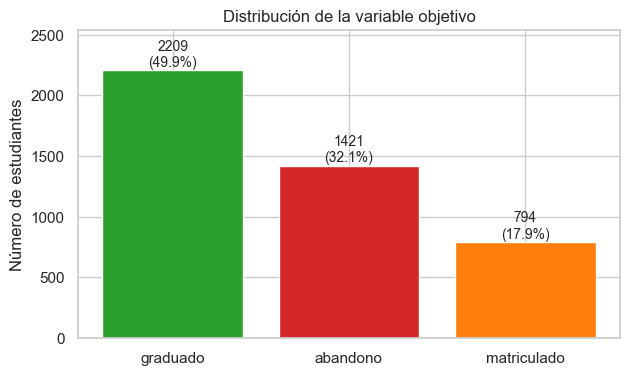

objetivo
graduado       2209
abandono       1421
matriculado     794
Name: count, dtype: int64


In [4]:
conteo = df['objetivo'].value_counts()
proporcion = df['objetivo'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(7, 4))
colores = {'graduado': '#2ca02c', 'abandono': '#d62728', 'matriculado': '#ff7f0e'}
ax.bar(conteo.index, conteo.values,
       color=[colores[c] for c in conteo.index])
for i, (clase, n) in enumerate(conteo.items()):
    ax.text(i, n + 30, f'{n}\n({proporcion[clase]:.1f}%)',
            ha='center', fontsize=10)
ax.set_ylabel('Número de estudiantes')
ax.set_title('Distribución de la variable objetivo')
ax.set_ylim(0, conteo.max() * 1.15)
plt.show()

print(conteo)

La clase más frecuente es `graduado` (50%), seguida de
`abandono` (32%) y `matriculado` (18%). Es un desbalance moderado pero relevante.

**Implicaciones.**

- No podemos usar **accuracy** como métrica principal: un clasificador que
  ignorase `matriculado` y predijese siempre entre las otras dos podría
  mantener un accuracy aparente alto mientras falla completamente en la
  clase minoritaria. Usaremos **F1 macro** (promedio no ponderado del F1
  por clase), que sí penaliza esa estrategia.
- Los modelos se configurarán con `class_weight='balanced'` para compensar
  parcialmente el desbalance durante el entrenamiento.

### 2.2 Variables académicas: inconsistencias y outliers

Las variables de asignaturas (matriculadas, evaluadas, aprobadas,
convalidadas) tienen inconsistencias que violan el sentido común y dan lugar a situaciones imposibles. A continuación se verifican una a una

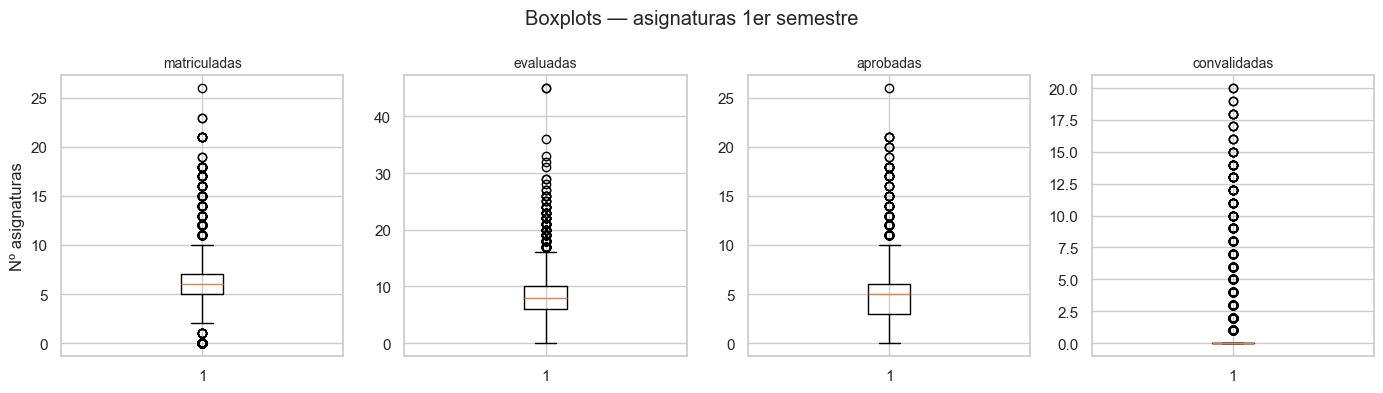

In [5]:
# Boxplots de las principales variables académicas, por semestre.
vars_academicas = [
    'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas',
    'asignaturas_1sem_aprobadas',    'asignaturas_1sem_convalidadas']

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, vars_academicas):
    ax.boxplot(df[col], vert=True)
    ax.set_title(col.replace('asignaturas_1sem_', ''), fontsize=10)
    ax.set_ylabel('Nº asignaturas' if ax is axes[0] else '')
fig.suptitle('Boxplots — asignaturas 1er semestre')
fig.tight_layout()
plt.show()

Se observan outliers en todas las variables, pero estos parecen ser más extremos en **evaluadas**
y en **convalidadas**.

In [6]:
print('Inconsistencias detectadas:')
for sem in ['1sem', '2sem']:
    eval_col = f'asignaturas_{sem}_evaluadas'
    mat_col = f'asignaturas_{sem}_matriculadas'
    apro_col = f'asignaturas_{sem}_aprobadas'
    conv_col = f'asignaturas_{sem}_convalidadas'
    n_outlier = (df[eval_col] > 20).sum()
    n_eval_mayor_mat = (df[eval_col] > df[mat_col]).sum()
    n_apro_mayor_eval = (df[apro_col] > df[eval_col]).sum()
    n_conv_alto = (df[conv_col] > 8).sum()
    print(f'\n{sem}:')
    print(f'  evaluadas > 20          : {n_outlier:5d}  (errores de registro)')
    print(f'  evaluadas > matriculadas: {n_eval_mayor_mat:5d}  (inconsistencia lógica) !!!!!!!')
    print(f'  aprobadas > evaluadas   : {n_apro_mayor_eval:5d}')
    print(f'  convalidadas > 8        : {n_conv_alto:5d}  (valores atípicos)')

Inconsistencias detectadas:

1sem:
  evaluadas > 20          :    60  (errores de registro)
  evaluadas > matriculadas:  2792  (inconsistencia lógica) !!!!!!!
  aprobadas > evaluadas   :     0
  convalidadas > 8        :   118  (valores atípicos)

2sem:
  evaluadas > 20          :    35  (errores de registro)
  evaluadas > matriculadas:  2660  (inconsistencia lógica) !!!!!!!
  aprobadas > evaluadas   :     0
  convalidadas > 8        :    82  (valores atípicos)


**Interpretación.** Hay tres tipos de inconsistencias:

1. **Outliers extremos** (`evaluadas > 20`): 60 filas en 1sem y 35 en 2sem.
   Los consideramos errores de registro. Se eliminan las filas.
2. **Evaluadas > matriculadas** (2792 filas en 1sem): es lógicamente
   imposible tener más asignaturas evaluadas de las que se está matriculado.
   Una interpretación posible es que 'evaluadas' sea una suma acumulativa de todas las asignaturas que lleva en el grado, y no solo para el semestre actual. En cualquier caso, una posible solución es reducir `evaluadas = min(evaluadas, matriculadas)`. Sin embargo, esto afecta a más del 50% de observaciones en nuestro dataset por lo que hay que tomar la decisión con cuiadado. Posteriormente, se comprobará si acotar el número de asignaturas evaluadas da mejores resultados o por el contrario es mejor idea dejarlos como están
3. **Aprobadas >= evaluadas** (0 casos): el dataset es consistente aquí por
   sí solo.
4. **Convalidadas > 8** (118 y 82 casos): son valores atípicos. Se acotan
   a 8 para no perder demasiada información.

La función `limpiar_vals_academicas` implementa estas cuatro reglas.

### 2.3 Nulos textuales en variables categóricas

`.isna()` no detecta los nulos porque están codificados como texto.
Buscamos manualmente las tres etiquetas que aparecen en el dataset
(`desconocido`, `en_blanco`, `otra_situacion`).

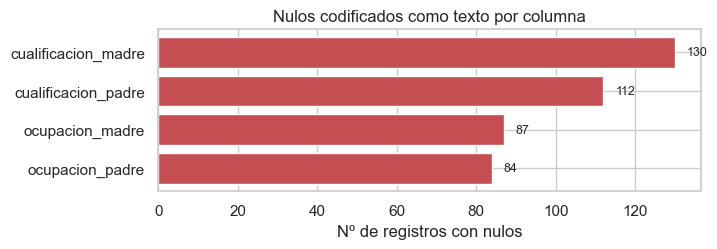

cualificacion_madre    130
cualificacion_padre    112
ocupacion_madre         87
ocupacion_padre         84
dtype: int64


In [7]:
TERMINOS_NULOS = ['desconocido', 'en_blanco', 'otra_situacion']
cat_cols = df.select_dtypes(include=object).columns

nulos_por_col = {}
for c in cat_cols:
    n = df[c].isin(TERMINOS_NULOS).sum()
    if n > 0:
        nulos_por_col[c] = n

if nulos_por_col:
    s = pd.Series(nulos_por_col).sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(7, 0.5 + 0.4*len(s)))
    ax.barh(s.index, s.values, color="r")
    for i, v in enumerate(s.values):
        ax.text(v + 3, i, f'{v}', va='center', fontsize=9)
    ax.set_xlabel('Nº de registros con nulos')
    ax.set_title('Nulos codificados como texto por columna')
    plt.show()
print(pd.Series(nulos_por_col).sort_values(ascending=False))

Los nulos se concentran en las cuatro variables de
información sobre los padres (ocupación y cualificación de padre y madre), con
entre 84 y 130 casos por variable.

**Implicación.** En vez de imputar con la moda o eliminar los registros,
agrupamos estas tres etiquetas en una sola categoría
`informacion_no_disponible`. La razón es que la ausencia del dato puede
ser en sí misma informativa. Esto lo implementa `unificar_nulls`.

### 2.4 Cardinalidad de variables categóricas

Muchas columnas categóricas tienen demasiadas etiquetas distintas, algunas con muy
pocos registros. Tras el one-hot encoding cada
categoría se convierte en una variable binaria, inflando la
dimensionalidad y generando sobreajuste. Por lo tanto, debemos tratarlo

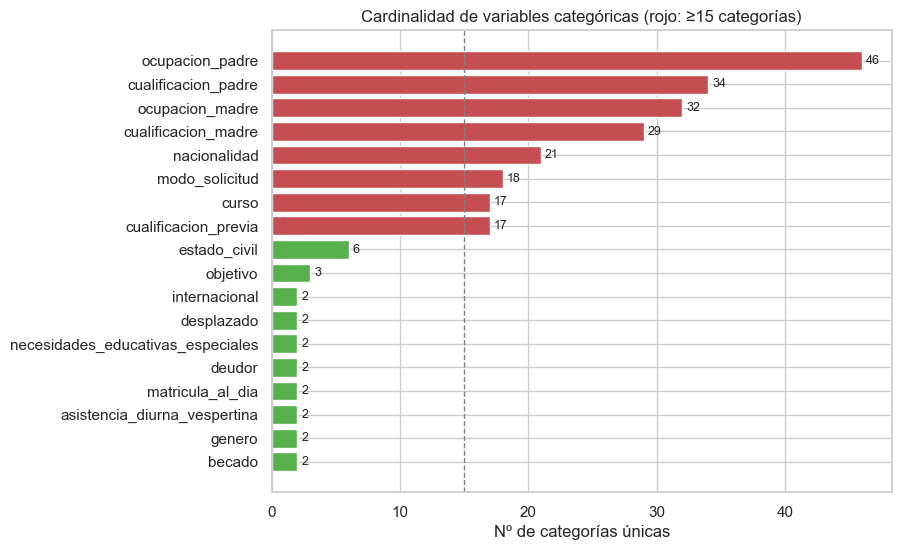

In [8]:
cardinalidades = df[cat_cols].nunique().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(8, 6))
colores_card = ['#c44e52' if v >= 15 else "#56b04c" for v in cardinalidades.values]
ax.barh(cardinalidades.index, cardinalidades.values, color=colores_card)

for i, v in enumerate(cardinalidades.values):
    ax.text(v + 0.3, i, f'{v}', va='center', fontsize=9)
    
ax.axvline(15, color='gray', ls='--', lw=1)
ax.set_xlabel('Nº de categorías únicas')
ax.set_title('Cardinalidad de variables categóricas (rojo: ≥15 categorías)')
plt.show()

Seis variables con cardinalidad ≥15: `ocupacion_padre` (46),
`cualificacion_padre` (34), `ocupacion_madre` (32), `cualificacion_madre`
(29), `nacionalidad` (21), `modo_solicitud` (18), `curso` (17) y
`cualificacion_previa` (17).

Veamos la distribución de frecuencias **dentro** de una de ellas
para confirmar que hay categorías con muy pocos registros:

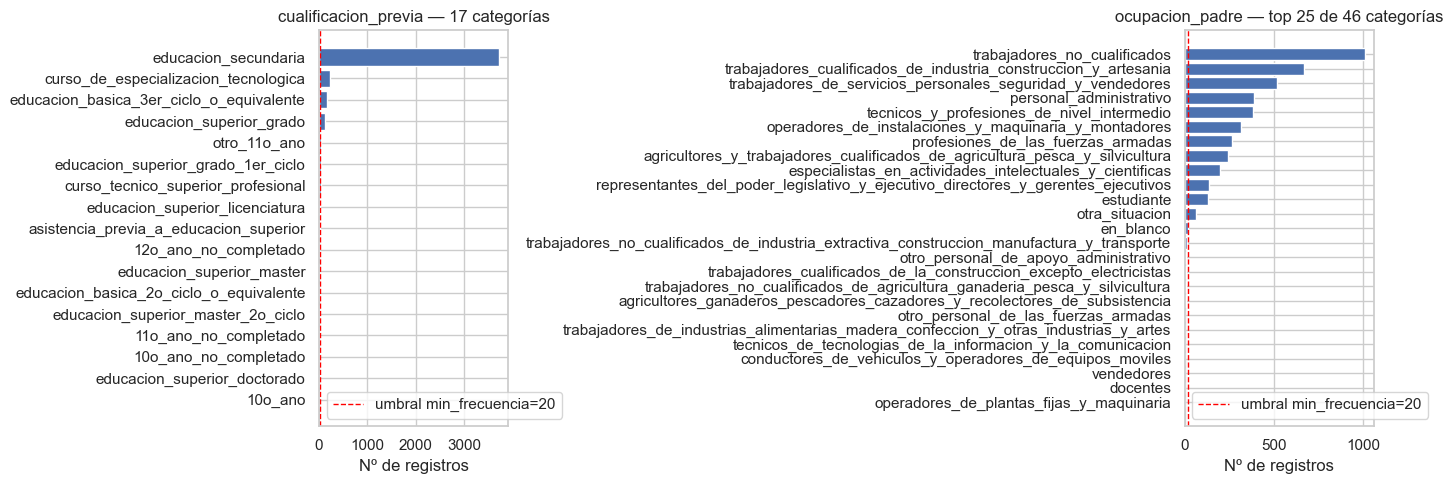

ocupacion_padre:  34/46 categorías con <20 registros
ocupacion_madre:  20/32 categorías con <20 registros
cualificacion_padre:  24/34 categorías con <20 registros
cualificacion_madre:  19/29 categorías con <20 registros


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# cualificacion_previa
vc = df['cualificacion_previa'].value_counts()
axes[0].barh(vc.index[::-1], vc.values[::-1], color='#4c72b0')
axes[0].axvline(20, color='red', ls='--', lw=1, label='umbral min_frecuencia=20')
axes[0].set_title(f'cualificacion_previa — {len(vc)} categorías')
axes[0].set_xlabel('Nº de registros')
axes[0].legend()

# ocupacion_padre (limitado a las top 20 por legibilidad)
vc2 = df['ocupacion_padre'].value_counts().head(25)
axes[1].barh(vc2.index[::-1], vc2.values[::-1], color='#4c72b0')
axes[1].axvline(20, color='red', ls='--', lw=1, label='umbral min_frecuencia=20')
axes[1].set_title(f'ocupacion_padre — top 25 de {df["ocupacion_padre"].nunique()} categorías')
axes[1].set_xlabel('Nº de registros')
axes[1].legend()

fig.tight_layout()
plt.show()

for col in ['ocupacion_padre', 'ocupacion_madre', 'cualificacion_padre', 'cualificacion_madre']:
    vc = df[col].value_counts()
    n_raras = (vc < 20).sum()
    print(f'{col}:  {n_raras}/{len(vc)} categorías con <20 registros')

En `cualificacion_previa` varios niveles académicos
similares están etiquetados bajo dsitintos nombres (distintos tipos de "superior", "técnico",
etc.) con pocos registros cada uno. En `ocupacion_padre` hay una larga
cola de categorías con <20 registros.

**Implicaciones.** Aplicamos dos estrategias distintas según la semántica:

- **Agrupación por significado** para `cualificacion_previa` y `modo_solicitud`:
  existe una jerarquía (niveles educativos, vías de acceso) que
  permite mapear por contenido a 4-5 grupos. Esto se lleva a cabo en
  `limpiar_cualificacion_previa` y `limpiar_modo_solicitud`.
- **Agrupación por frecuencia** para las variables de padres: no hay una
  jerarquía obvia entre ocupaciones, así que fusionamos las categorías
  con <20 registros bajo `otras_categorias`. Esto lo hace `limpiar_info_padres`.

Además, `nacionalidad` tiene 21 categorías pero el ~98% son
portugueses. Es redundante teniendo la variable binaria `internacional`, así
que la eliminamos directamente.

In [10]:
print(df['nacionalidad'].value_counts(normalize=True).head().round(3) * 100)

nacionalidad
portuguesa      97.5
brasilena        0.9
santotomense     0.3
caboverdiana     0.3
espanola         0.3
Name: proportion, dtype: float64


### 2.5 Variables numéricas

Estudiamos las distribuciones de las principales variables numéricas
continuas para entender sus rangos, asimetrías y modas.

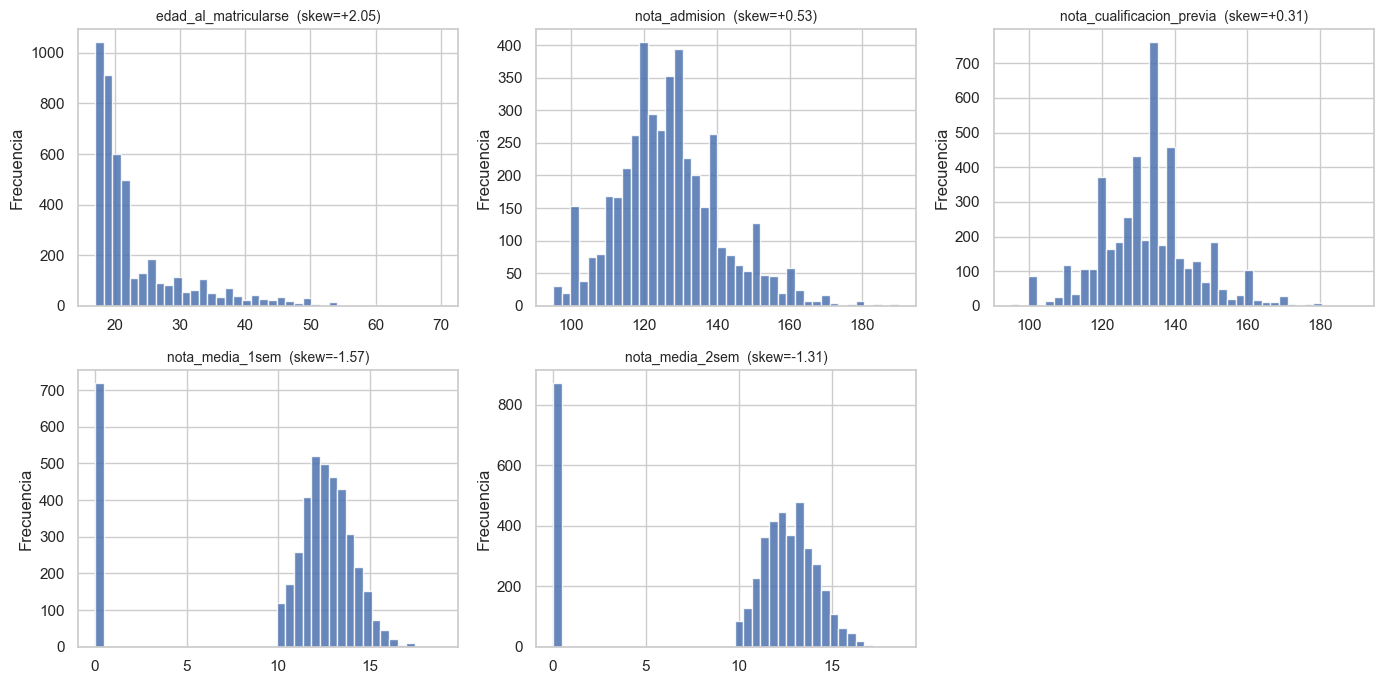

       edad_al_matricularse  nota_admision  nota_cualificacion_previa  \
count               4424.00        4424.00                    4424.00   
mean                  23.27         126.98                     132.61   
std                    7.59          14.48                      13.19   
min                   17.00          95.00                      95.00   
25%                   19.00         117.90                     125.00   
50%                   20.00         126.10                     133.10   
75%                   25.00         134.80                     140.00   
max                   70.00         190.00                     190.00   

       nota_media_1sem  nota_media_2sem  
count          4424.00          4424.00  
mean             10.64            10.23  
std               4.84             5.21  
min               0.00             0.00  
25%              11.00            10.75  
50%              12.29            12.20  
75%              13.40            13.33  
max   

In [11]:
vars_continuas = ['edad_al_matricularse', 'nota_admision', 'nota_cualificacion_previa',
    'nota_media_1sem', 'nota_media_2sem']

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()
for ax, col in zip(axes, vars_continuas):
    ax.hist(df[col], bins=40, color="b", alpha=0.85, edgecolor='white')
    skew = df[col].skew()
    ax.set_title(f'{col}  (skew={skew:+.2f})', fontsize=10)
    ax.set_ylabel('Frecuencia')
axes[-1].axis('off')
fig.tight_layout()
plt.show()

print(df[vars_continuas].describe().round(2))

**Lecturas clave:**

- **`edad_al_matricularse` skew=+2.05.** Asimetría fuerte a la derecha.
  La gran mayoría entra con 17-22 años, pero hay una cola hasta los 70.
- **`nota_media_1sem` y `nota_media_2sem` skew ≈ -1.5.** Asimetría a la
  izquierda por una acumulación de ceros (abandonos prematuros?). Se
  ven dos modos: uno en 0.0 y otro entre 10 y 15. Este patrón bimodal es
  clave para decidir cómo construir el dataset de regresión — lo
  examinamos con detalle a continuación.
- **`nota_admision` y `nota_cualificacion_previa`**: distribuciones
  aproximadamente simétricas centradas en 127 y 132 puntos respectivamente,
  sin outliers relevantes.

#### Bimodalidad en las notas medias — justificación de las decisiones para regresión

El histograma de `nota_media_1sem` mostraba dos modos. Si vemos el
histograma por clase objetivo, la razón queda clara.

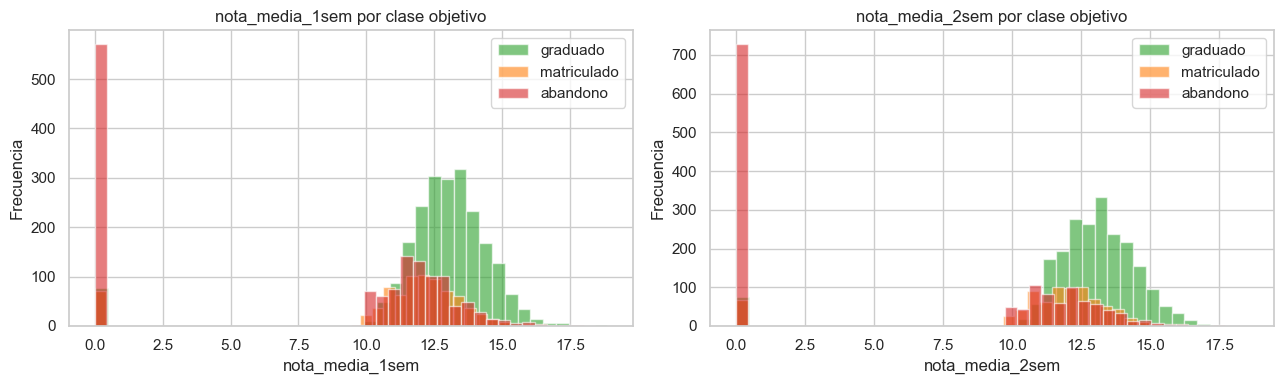


nota_media_1sem = 0.0:
objetivo
abandono       570
graduado        77
matriculado     71
Name: count, dtype: int64

nota_media_2sem = 0.0:
objetivo
abandono       727
graduado        75
matriculado     68
Name: count, dtype: int64


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ['nota_media_1sem', 'nota_media_2sem']):
    for clase, color in [('graduado', '#2ca02c'),
                         ('matriculado', '#ff7f0e'),
                         ('abandono', '#d62728')]:
        sub = df.loc[df['objetivo'] == clase, col]
        ax.hist(sub, bins=40, alpha=0.6, label=clase, color=color)
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')
    ax.set_title(f'{col} por clase objetivo')
    ax.legend()
fig.tight_layout()
plt.show()

# Cuantificamos los ceros
for col in ['nota_media_1sem', 'nota_media_2sem']:
    print(f'\n{col} = 0.0:')
    print(df[df[col] == 0.0]['objetivo'].value_counts())

La moda en 0.0 está prácticamente compuesto por estudiantes
que terminaron en `abandono`. Un 0.0 en nota media no es una nota baja,
lo consideramos directamente una ausencia de evaluacion. El estudiante abandonó antes de ser
evaluado.

**Implicación para la tarea de regresión:** si dejáramos estos
registros en el dataset de regresión, estaríamos intentando ajustar una
función continua sobre **dos poblaciones distintas**. Los modelos tirarían
las predicciones hacia abajo para tratar de acomodar los
ceros, destrozando el ajuste sobre los estudiantes que sí se presentaron.

Por eso `generar_data_regresion` filtra los registros con
`nota_media_1sem == 0` **o** `nota_media_2sem == 0`.

En clasificación, por el contrario, esos ceros se **mantienen** porque son
clave para predecir la clase `abandono`.

### 2.6 Variables socioeconómicas y su relación con el objetivo

Varias variables binarias (becado, deudor, matrícula al día, etc.) tienen
un potencial discriminante importante. Miramos la tasa de cada clase
objetivo dentro de cada grupo.

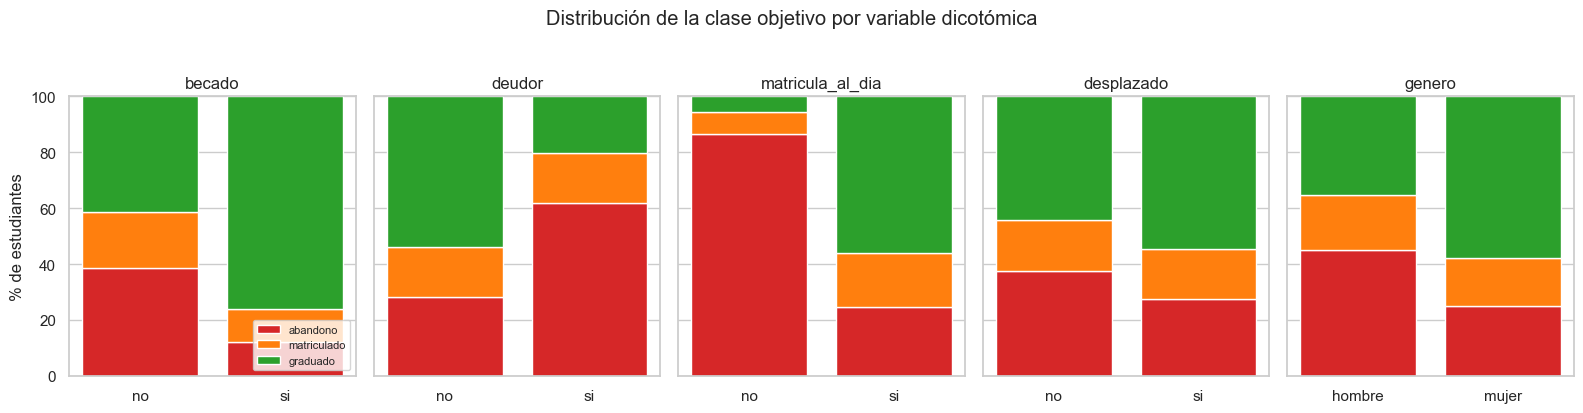

In [13]:
vars_dicotomicas = ['becado', 'deudor', 'matricula_al_dia', 'desplazado', 'genero']
fig, axes = plt.subplots(1, len(vars_dicotomicas), figsize=(16, 4), sharey=True)

colores_obj = {'graduado': '#2ca02c', 'matriculado': '#ff7f0e', 'abandono': '#d62728'}

for ax, col in zip(axes, vars_dicotomicas):
    ct = pd.crosstab(df[col], df['objetivo'], normalize='index') * 100
    ct = ct[['abandono', 'matriculado', 'graduado']]  # orden fijo
    bottom = np.zeros(len(ct))
    for clase in ct.columns:
        ax.bar(ct.index, ct[clase], bottom=bottom,
               label=clase, color=colores_obj[clase])
        bottom += ct[clase].values
    ax.set_title(col)
    ax.set_ylim(0, 100)
    if ax is axes[0]:
        ax.set_ylabel('% de estudiantes')
        ax.legend(loc='lower right', fontsize=8)
        
fig.suptitle('Distribución de la clase objetivo por variable dicotómica', y=1.03)
fig.tight_layout()
plt.show()

**Observaciones:**

- **`deudor=si`: 62% abandono** vs 28% si no es deudor..
- **`matricula_al_dia=no`: 87% abandono**. Parece que será una de las variables más informativas
del dataset; un estudiante que no tiene la matrícula al día abandona casi seguro.
- **`becado=si`: 76% graduación** vs 41% si no es becado. No necesariamente tiene porque ser causal pero 
  estando becado es menos probable abandonar.
- **`desplazado` y `genero`** tienen efectos menos relevantes.

**Implicación.** Estas variables aparecerán probablemente entre las más importantes
en los modelos de clasificación. No serán preprocesadas en especial más
allá del one-hot encoding estándar.

### 2.7 Multicolinealidad entre variables académicas

Las variables que describen el rendimiento del primer semestre
(matriculadas, evaluadas, aprobadas, nota media) están lógicamente
relacionadas entre sí. Medimos cuánto.

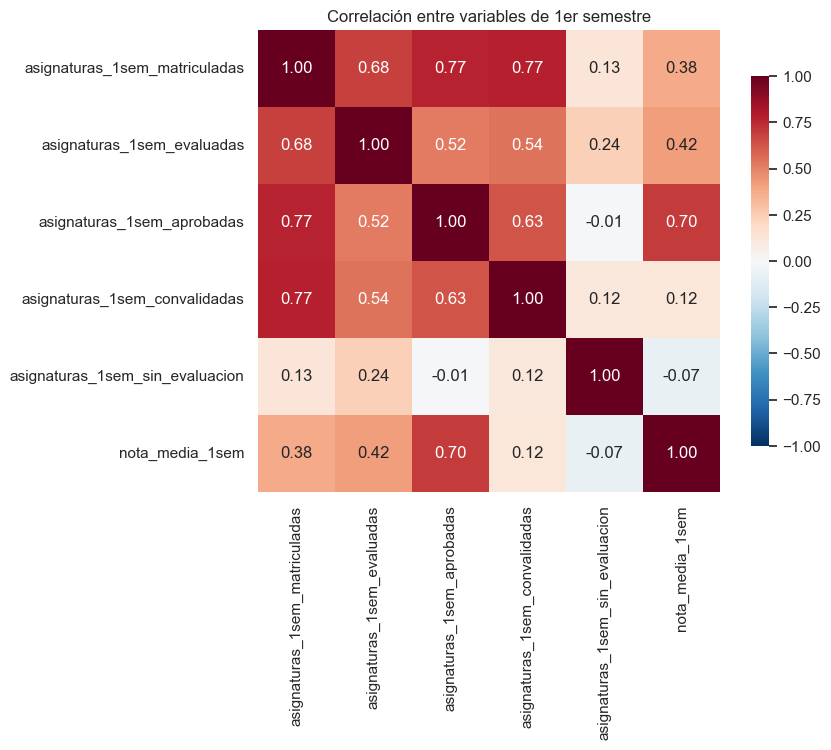

In [14]:
vars_1sem = [
    'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas',
    'asignaturas_1sem_aprobadas',    'asignaturas_1sem_convalidadas',
    'asignaturas_1sem_sin_evaluacion', 'nota_media_1sem']

corr_1sem = df[vars_1sem].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_1sem, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Correlación entre variables de 1er semestre')
plt.show()

Observamos correlaciones muy altas entre:

- `matriculadas - aprobadas` (0.77)
- `nota_media_1sem - aprobadas` (0.70)

**Implicaciones para el modelado.**

- Los modelos lineales sin regularización (ej. Regresión Lineal Simple) serán más inestables.
  Por eso incluimos **Ridge** (L2 estabiliza
  coeficientes), **Lasso** (L1 fuerza a cero los redundantes) y
  **ElasticNet** (combinación de los anteriores).
- El **Random Forest** es robusto a multicolinealidad por el *bagging*
  y el submuestreo de variables en cada split. Pero tiene una consecuencia
  secundaria: la importancia Gini se reparte entre
  variables redundantes, así que hay que interpretarla con cuidado.
- **KNN** es sensible a features redundantes porque inflan la distancia. Se ve en el notebook de
  clasificación.

### 2.8 Variables macroeconómicas: baja varianza

El dataset incluye tres variables contextuales agregadas: tasa de
desempleo, inflación y PIB. Comprobamos su variabilidad.

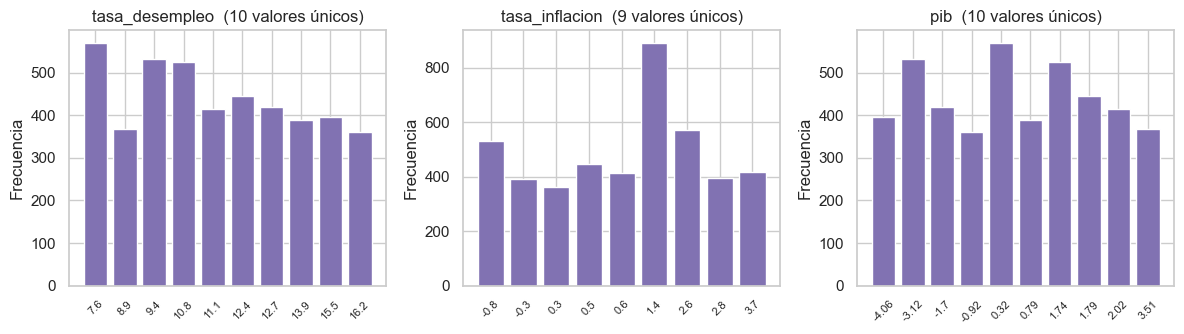

       tasa_desempleo  tasa_inflacion      pib
count         4424.00         4424.00  4424.00
mean            11.57            1.23     0.00
std              2.66            1.38     2.27
min              7.60           -0.80    -4.06
25%              9.40            0.30    -1.70
50%             11.10            1.40     0.32
75%             13.90            2.60     1.79
max             16.20            3.70     3.51


In [15]:
vars_macro = ['tasa_desempleo', 'tasa_inflacion', 'pib']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col in zip(axes, vars_macro):
    vals = df[col].value_counts().sort_index()
    ax.bar(vals.index.astype(str), vals.values, color='#8172b2')
    ax.set_title(f'{col}  ({df[col].nunique()} valores únicos)')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.set_ylabel('Frecuencia')
fig.tight_layout()
plt.show()

print(df[vars_macro].describe().round(2))

Sólo 9-10 valores únicos en cada una. Su variabilidad entre estudiantes es por ello baja.

**Decisión.** Mantenemos estas variables porque pueden capturar efectos
de contexto económico pero esperamos que su importancia sea relativamente baja en los modelos.

### 2.9 Resumen de decisiones justificadas por el EDA

| Observación del EDA | Decisión de preprocesado | Función |
|---|---|---|
| Target desbalanceado 50/32/18 | Métrica F1 macro, `class_weight='balanced'` | (notebooks 2-3) |
| Nulos textuales en info parental | Agrupar bajo `informacion_no_disponible` | `unificar_nulls` |
| Target como string | Codificar a {0,1,2} | `codificar_objetivo` |
| Outliers `evaluadas > 20` y `eval > mat` | Eliminar outliers, recortar con `np.minimum` | `limpiar_vals_academicas` |
| `convalidadas > 8` atípico | Recortar a 8 | `limpiar_vals_academicas` |
| Alta cardinalidad en cualificación y vía de acceso | Agrupación semántica | `limpiar_cualificacion_previa`, `limpiar_modo_solicitud` |
| Cola de categorías raras en info parental | Agrupar las <20 en `otras_categorias` | `limpiar_info_padres` |
| `nacionalidad` 98% portuguesa + redundante con `internacional` | Eliminar columna | `limpiar_dataset` |
| Bimodalidad por ceros en notas medias | Filtrar abandonos del dataset de regresión | `generar_data_regresion` |
| Variables 2sem contemporáneas al target | Eliminar del dataset de regresión | `generar_data_regresion` |



## 3. Limpieza del dataset

Aplicamos `clean_data.limpiar_dataset`, que orquesta todas las funciones en
el orden correcto. Verificamos el efecto paso a paso.

In [16]:
print(f'Shape inicial: {df.shape}')
df_limpio = clean_data.limpiar_dataset(df)
print(f'Shape final:   {df_limpio.shape}')
print(f'Filas eliminadas: {len(df) - len(df_limpio)} (outliers académicos)')
print(f'Columnas eliminadas: {df.shape[1] - df_limpio.shape[1]} (nacionalidad)')

Shape inicial: (4424, 37)
Shape final:   (4349, 36)
Filas eliminadas: 75 (outliers académicos)
Columnas eliminadas: 1 (nacionalidad)


In [17]:
print('Cardinalidad ANTES vs DESPUÉS de la limpieza:')
cols_reducir = ['cualificacion_previa', 'modo_solicitud',
                'ocupacion_padre', 'ocupacion_madre',
                'cualificacion_padre', 'cualificacion_madre']

for c in cols_reducir:
    antes = df[c].nunique()
    despues = df_limpio[c].nunique()
    print(f'{c:25s}{antes:3d} --> {despues:3d}')

Cardinalidad ANTES vs DESPUÉS de la limpieza:
cualificacion_previa      17 -->   5
modo_solicitud            18 -->   5
ocupacion_padre           46 -->  13
ocupacion_madre           32 -->  13
cualificacion_padre       34 -->  10
cualificacion_madre       29 -->  11


In [18]:
#verificamos que no hay nulos textuales no agrupados
restantes = 0
for c in df_limpio.select_dtypes(include=object).columns:
    restantes += df_limpio[c].isin(['desconocido', 'en_blanco', 'otra_situacion']).sum()
print(f'Nulos textuales restantes: {restantes}')
print(f'Valores en "informacion_no_disponible": '
      f'{(df_limpio == "informacion_no_disponible").sum().sum()}')

Nulos textuales restantes: 0
Valores en "informacion_no_disponible": 404


## 4. Generación de los datasets de salida

### 4.1 Dataset de clasificación

Se mantienen todas las variables, incluidas las notas 0.0, porque son posiblemente los valores más informativos para la clase `abandono`. Split **80/20 estratificado**
para preservar las proporciones en train y test.

In [19]:
df_clf_train, df_clf_test = clean_data.generar_data_clasificacion(
    df_limpio, output_dir=str(PROCESSED_DIR),
    test_size=0.20, random_state=42,
)
print(f'Train: {df_clf_train.shape[0]} filas')
print(f'Test:  {df_clf_test.shape[0]} filas')

# Verificamos que la estratificación preserva las proporciones
prop_train = (df_clf_train['objetivo'].value_counts(normalize=True) * 100).round(2)
prop_test  = (df_clf_test['objetivo'].value_counts(normalize=True) * 100).round(2)
print(f'\n% clase en train: {dict(prop_train)}')
print(f'% clase en test:  {dict(prop_test)}')

print('\nRecordemos que {0:abandono, 1:matriculado, 2:graduado}')

Train: 3479 filas
Test:  870 filas

% clase en train: {2: 49.7, 0: 32.22, 1: 18.08}
% clase en test:  {2: 49.77, 0: 32.18, 1: 18.05}

Recordemos que {0:abandono, 1:matriculado, 2:graduado}


### 4.2 Dataset de regresión

Dos filtros:

1. **Anti data-leakage**: eliminamos todas las variables del 2º semestre (incluida `objetivo`)
   distintas del target, porque son contemporáneas a él.
2. **Anti sesgo por 0.0**: eliminamos los registros con
   `nota_media_1sem == 0` o `nota_media_2sem == 0`, tal y como se detalla en la sección 2.5.

In [20]:
df_reg_train, df_reg_test = clean_data.generar_data_regresion(
    df_limpio, output_dir=str(PROCESSED_DIR),
    test_size=0.20, random_state=0)

print(f'Train: {df_reg_train.shape[0]} filas x {df_reg_train.shape[1]} columnas')
print(f'Test:  {df_reg_test.shape[0]} filas')
print(f'\nFilas eliminadas por filtrado de abandonos: '
      f'{len(df_limpio) - len(df_reg_train) - len(df_reg_test)}')

# Distribución del target tras filtrar
y = df_reg_train['nota_media_2sem']
print(f'\nTarget nota_media_2sem (train):')
print(f' rango: {y.min():.2f} a {y.max():.2f}')
print(f' media: {y.mean():.2f}, std: {y.std():.2f}')
print(f' valores = 0.0: {(y == 0.0).sum()}  (esperado: 0)')

Train: 2750 filas x 31 columnas
Test:  688 filas

Filas eliminadas por filtrado de abandonos: 911

Target nota_media_2sem (train):
 rango: 10.00 a 18.57
 media: 12.78, std: 1.39
 valores = 0.0: 0  (esperado: 0)


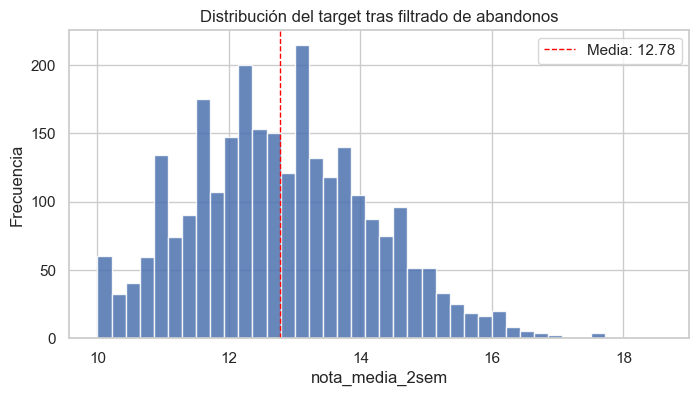

In [21]:
# Confirmación de que el target de regresión ya no es bimodal
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_reg_train['nota_media_2sem'], bins=40,
        color='b', alpha=0.85, edgecolor='white')
ax.axvline(df_reg_train['nota_media_2sem'].mean(),
           color='red', ls='--', lw=1,
           label=f'Media: {df_reg_train["nota_media_2sem"].mean():.2f}')
ax.set_xlabel('nota_media_2sem')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución del target tras filtrado de abandonos')
ax.legend()
plt.show()

La distribución es ahora unimodal, concentrada entre 10 y 18 puntos. Los modelos regresión podrán ahora ajustarse sin tener que acomodarse a dos poblaciones 'distintas'

## 5. Verificación final

In [22]:
for f in sorted(PROCESSED_DIR.glob('*.csv')):
    size_kb = f.stat().st_size / 1024
    print(f'  {f.name:50s}  {size_kb:>8.1f} KB')


  datos_limpios_clasificacion_test.csv                   275.3 KB
  datos_limpios_clasificacion_train.csv                 1097.0 KB
  datos_limpios_regresion_test.csv                       212.7 KB
  datos_limpios_regresion_train.csv                      848.0 KB


---

Con esto los datos están listos. Los notebooks `02_clasificacion.ipynb` y
`03_regresion.ipynb` asumen que los cuatro ficheros existen en
`data/processed/`.